# Квадрокоптер 4×22″: максимальне корисне навантаження

**Тестове завдання №1** · параметрична модель, чутливість, Monte Carlo, оцінка достовірності

Вихідних даних (двигуни, акумулятор, рама) не надано. Тому всі вхідні величини задано **як параметри з діапазонами** і позначено статусом:

| Статус | Значення |
|---|---|
| `verified` | з завдання, фізична константа або вибір геометрії |
| `requirement` | вимога місії / запас, який задає замовник |
| `hypothesis` | припущення, яке потребує експерименту |

Розглядаються **3 референсні конфігурації** (A легка, B середня, C важка). Усі числа в цьому ноутбуку є **розрахунковими оцінками на основі гіпотез**, експериментально нічого не підтверджено.

**Структура:** 1) постановка · 2) параметри · 3) модель · 4) розв'язок і перевірка розмірностей · 5) результат · 6) чутливість · 7) Monte Carlo · 8) достовірність, припущення, умови достовірності · 9) експерименти та обмеження · 10) технічний звіт

## 1. Постановка задачі

Нехай $m_p$ це корисне навантаження, $\theta$ вектор параметрів. Конфігурація допустима, якщо виконано всі безрозмірні обмеження

$$g_i(m_p,\theta)=1-\frac{\text{попит}_i}{\text{ресурс}_i}\ \ge 0,\qquad i=1\ldots 9 .$$

Обмеження незалежні, тож граничне навантаження визначає найжорсткіше з них:

$$m_{p,\max}(\theta)=\min_i m_i^*,\qquad g_i(m_i^*,\theta)=0 .$$

Кожне $m_i^*$ знаходиться як корінь одновимірного рівняння (сітка + `brentq`, перевірка власною бісекцією). Невизначеність $\theta$ (діапазони $[\theta_{\min},\theta_{\max}]$) переноситься на $m_{p,\max}$ через OAT-чутливість і Monte Carlo.

| № | Обмеження | Попит / ресурс |
|---|---|---|
| 1 | запас тяги | $k_T\,m g$ / $N\,T_{\max}$ |
| 2 | струм мотора/ESC | $I_{hover}$ / $\min(I_{cont,m},I_{cont,esc})$ |
| 3 | струм батареї | $I_{bat}$ / $C_{cont}\,Cap$ |
| 4 | температура мотора | $P_{loss}R_{th}$ / $(T_{w,max}-T_{amb})$ |
| 5 | температура ESC | $P_{esc}R_{th,esc}$ / $(T_{esc,max}-T_{amb})$ |
| 6 | час висіння | $t_{req}$ / $t_{hover}$ |
| 7 | вигин променя | $\sigma\,SF$ / $\sigma_{all}$ |
| 8 | зминання під болтами | $\sigma_b\,SF$ / $\sigma_{bear}$ |
| 9 | прогин променя | $\delta$ / $(\delta_{lim}L)$ |

In [16]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.optimize import brentq
from scipy.stats import spearmanr
from IPython.display import display, Markdown
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3})
os.makedirs('report/figures', exist_ok=True)
def savefig(name): plt.savefig(f'report/figures/{name}.png', dpi=150, bbox_inches='tight')

## 2. Параметри конфігурацій

Кожен параметр: `value`, `lo`, `hi`, `unit`, `status`, `source`. Параметри з `lo == hi` вважаються фіксованими.
Значення Kv підібрані так, щоб максимальна тяга двигуна відповідала класам ≈ 8.7 / 10 / 11 кгс (це припущення, а не дані виробника).

In [17]:
@dataclass
class Par:
    value: float; lo: float; hi: float; unit: str; status: str; source: str

def P(v, lo=None, hi=None, unit='-', status='hypothesis', src=''):
    return Par(v, v if lo is None else lo, v if hi is None else hi, unit, status, src)

def common():
    H='hypothesis'
    return dict(
    g=P(9.81,9.78,9.83,'m/s2','verified','константа'),
    rho=P(1.225,1.00,1.25,'kg/m3','verified','ISA; 1.0 = спека/висота'),
    T_amb=P(25,-10,40,'degC',H,'умови експлуатації'),
    D=P(22*0.0254,unit='m',status='verified',src='завдання: 22"'),
    N=P(4,unit='-',status='verified',src='завдання: 4 двигуни'),
    C_T=P(0.11,0.08,0.14,'-',H,'типово для великих CF-пропелерів'),
    C_P=P(0.050,0.040,0.065,'-',H,'типово; FoM = C_T^1.5/(sqrt(pi/2)*C_P) ~ 0.58'),
    m_prop=P(0.10,0.08,0.14,'kg',H,'каталожне'),
    rho_cf=P(1600,1500,1700,'kg/m3',H,'вуглепластик'),
    E=P(70e9,50e9,100e9,'Pa',H,'ефективний модуль труби'),
    sigma_all=P(150e6,100e6,250e6,'Pa',H,'допустиме при вигині зі знижкою на стик'),
    sigma_bear=P(100e6,60e6,150e6,'Pa',H,'зминання стінки CF під болтом'),
    SF=P(1.5,1.5,2.0,'-','requirement','запас міцності'),
    n_load=P(2.0,1.5,3.0,'-',H,'перевантаження при маневрі'),
    defl_lim=P(0.03,0.02,0.05,'L','requirement','допустимий прогин, частка L'),
    d_bolt=P(0.005,unit='m',status='verified',src='M5'),
    n_pairs=P(1,unit='-',status='verified',src='пар болтів'),
    a_joint=P(0.06,0.04,0.08,'m',H,'відстань між болтами'),
    m_plate=P(0.7,0.4,1.0,'kg',H,'пластини'),
    m_av=P(0.6,0.4,0.9,'kg',H,'польотник, GPS, радіо'),
    m_misc=P(1.2,0.6,1.8,'kg',H,'проводка, шасі, кріплення'),
    r_core=P(0.12,0.08,0.20,'m',H,'радіус центрального тіла'),
    Vc=P(3.7,3.6,3.8,'V','verified','номінал комірки'),
    e_spec=P(140,120,180,'Wh/kg',H,'питома енергія батареї'),
    DoD=P(0.8,0.7,0.9,'-',H,'глибина розряду'),
    f_sw=P(0.010,0.005,0.020,'-',H,'комутаційні втрати ESC, частка від P_in'),
    P_av=P(40,30,60,'W',H,'бортова електроніка'),
    t_req=P(10,unit='min',status='requirement',src='ВИМОГА МІСІЇ (задати)'),
    kT_req=P(1.8,1.6,2.2,'-','requirement','запас тяги T_max/(m g)'),
    duty_max=P(0.95,0.90,1.00,'-',H,'макс. шпаруватість ESC'),
    T_w_max=P(120,100,140,'degC',H,'макс. темп. обмотки'),
    T_esc_max=P(100,85,110,'degC',H,'макс. темп. ESC'),
    C_cont=P(10,6,15,'C',H,'довготривалий розряд'))

def cfg(name, **kw):
    p = common(); p.update(kw); return dict(name=name, p=p)

def configs():
    H='hypothesis'; V='verified'
    A = cfg('A (легка, 12S 16Ah)',
      L_arm=P(0.55,unit='m',status=V,src='вибір'), d_o=P(0.028,unit='m',status=V,src='CF O28'),
      t_wall=P(0.0015,0.0012,0.0018,'m',V,'стінка 1.5 мм'),
      m_motor=P(0.55,0.50,0.60,'kg',H,'клас ~7 кгс'), m_esc=P(0.15,0.12,0.18,'kg',H,'ESC 60-80A'),
      S=P(12,unit='-',status=V,src='12S'), Cap=P(16,unit='Ah',status=V,src='16 Аг'),
      R_pack=P(0.018,0.012,0.025,'Ohm',H,'опір батареї'),
      Kv=P(135,130,140,'rpm/V',H,'22" на 12S, клас ~8.7 кгс'), Rm=P(0.060,0.050,0.075,'Ohm',H,'опір обмотки'),
      I0=P(1.0,0.7,1.5,'A',H,'холостий хід'),
      I_cont_m=P(35,30,40,'A',H,'довготр. мотор'), I_peak_m=P(60,50,70,'A',H,'пік мотор'),
      I_cont_esc=P(60,50,70,'A',H,'довготр. ESC'), I_peak_esc=P(80,70,90,'A',H,'пік ESC'),
      Rth_m=P(0.8,0.5,1.2,'K/W',H,'обмотка-повітря'), Rth_esc=P(6,4,9,'K/W',H,'ESC-повітря'), R_on=P(0.005,0.003,0.007,'Ohm',H,'опір відкритого ключа ESC'))
    B = cfg('B (середня, 12S 22Ah)',
      L_arm=P(0.60,unit='m',status=V,src='вибір'), d_o=P(0.030,unit='m',status=V,src='CF O30'),
      t_wall=P(0.002,0.0016,0.0024,'m',V,'стінка 2 мм'),
      m_motor=P(0.75,0.70,0.80,'kg',H,'клас ~9 кгс'), m_esc=P(0.20,0.16,0.24,'kg',H,'ESC 80-100A'),
      S=P(12,unit='-',status=V,src='12S'), Cap=P(22,unit='Ah',status=V,src='22 Аг'),
      R_pack=P(0.015,0.010,0.022,'Ohm',H,'опір батареї'),
      Kv=P(145,139,151,'rpm/V',H,'22" на 12S, клас ~10 кгс'), Rm=P(0.045,0.038,0.055,'Ohm',H,'опір обмотки'),
      I0=P(1.2,0.8,1.8,'A',H,'холостий хід'),
      I_cont_m=P(45,38,52,'A',H,'довготр. мотор'), I_peak_m=P(75,65,85,'A',H,'пік мотор'),
      I_cont_esc=P(80,70,90,'A',H,'довготр. ESC'), I_peak_esc=P(100,90,110,'A',H,'пік ESC'),
      Rth_m=P(0.7,0.45,1.0,'K/W',H,'обмотка-повітря'), Rth_esc=P(5,3.5,8,'K/W',H,'ESC-повітря'), R_on=P(0.004,0.0025,0.006,'Ohm',H,'опір відкритого ключа ESC'))
    C = cfg('C (важка, 14S 16Ah)',
      L_arm=P(0.65,unit='m',status=V,src='вибір'), d_o=P(0.035,unit='m',status=V,src='CF O35'),
      t_wall=P(0.0025,0.002,0.003,'m',V,'стінка 2.5 мм'),
      m_motor=P(0.95,0.90,1.00,'kg',H,'клас ~11 кгс'), m_esc=P(0.25,0.20,0.30,'kg',H,'ESC 80-120A'),
      S=P(14,unit='-',status=V,src='14S'), Cap=P(16,unit='Ah',status=V,src='16 Аг'),
      R_pack=P(0.022,0.015,0.030,'Ohm',H,'опір батареї'),
      Kv=P(130,125,135,'rpm/V',H,'22" на 14S, клас ~11 кгс'), Rm=P(0.035,0.028,0.045,'Ohm',H,'опір обмотки'),
      I0=P(1.5,1.0,2.2,'A',H,'холостий хід'),
      I_cont_m=P(60,50,70,'A',H,'довготр. мотор'), I_peak_m=P(90,80,100,'A',H,'пік мотор'),
      I_cont_esc=P(80,70,90,'A',H,'довготр. ESC'), I_peak_esc=P(120,100,130,'A',H,'пік ESC'),
      Rth_m=P(0.6,0.4,0.9,'K/W',H,'обмотка-повітря'), Rth_esc=P(4.5,3,7,'K/W',H,'ESC-повітря'), R_on=P(0.003,0.002,0.005,'Ohm',H,'опір відкритого ключа ESC'))
    return [A,B,C]

In [18]:
def flatten(p, ovr=None):
    v = {k: x.value for k,x in p.items()}
    if ovr: v.update(ovr)
    return v

CFG = configs()
def params_table(c):
    return pd.DataFrame([dict(param=k, value=p.value, lo=p.lo, hi=p.hi, unit=p.unit, status=p.status, source=p.source)
                         for k,p in c['p'].items()]).set_index('param')
tab = params_table(CFG[1])
print('Конфігурація B: статуси параметрів ->', dict(tab.status.value_counts()))
display(tab.head(12))

Конфігурація B: статуси параметрів -> {'hypothesis': np.int64(35), 'verified': np.int64(12), 'requirement': np.int64(4)}


,value,lo,hi,unit,status,source
param,,,,,,
g,9.810000e+00,9.780000e+00,9.830000e+00,m/s2,verified,константа
rho,1.225000e+00,1.000000e+00,1.250000e+00,kg/m3,verified,ISA; 1.0 = спека/висота
T_amb,2.500000e+01,-1.000000e+01,4.000000e+01,degC,hypothesis,умови експлуатації
D,5.588000e-01,5.588000e-01,5.588000e-01,m,verified,"завдання: 22"""
N,4.000000e+00,4.000000e+00,4.000000e+00,-,verified,завдання: 4 двигуни
C_T,1.100000e-01,8.000000e-02,1.400000e-01,-,hypothesis,типово для великих CF-пропелерів
C_P,5.000000e-02,4.000000e-02,6.500000e-02,-,hypothesis,типово; FoM = C_T^1.5/(sqrt(pi/2)*C_P) ~ 0.58
m_prop,1.000000e-01,8.000000e-02,1.400000e-01,kg,hypothesis,каталожне
rho_cf,1.600000e+03,1.500000e+03,1.700000e+03,kg/m3,hypothesis,вуглепластик


## 3. Модель

### 3.1 Маса та інерція
$$m_{arm}=\rho_{cf}\,\tfrac{\pi}{4}\big(d_o^2-d_i^2\big)L,\quad d_i=d_o-2t,\qquad m_{batt}=\frac{S\,V_c\,Cap}{e_{spec}}$$
$$I_{xx}=N\Big(m_{tip}\tfrac{L^2}{2}+m_{arm}\tfrac{L^2}{6}\Big)+0.4\,m_{core}r^2,\qquad I_{zz}=N\Big(m_{tip}L^2+m_{arm}\tfrac{L^2}{3}\Big)+0.4\,m_{core}r^2$$
Припущення: X-схема (45°), вузол мотор+ESC+гвинт на кінці променя, центральне тіло як куля, зсув ЦМ по $z$ не враховано.

In [19]:
def model_mass(v, m_p):
    A = np.pi/4*(v['d_o']**2-(v['d_o']-2*v['t_wall'])**2)
    m_arm = v['rho_cf']*A*v['L_arm']
    m_tip = v['m_motor']+v['m_esc']+v['m_prop']
    m_batt = v['S']*v['Vc']*v['Cap']/v['e_spec']
    m_core = v['m_plate']+v['m_av']+v['m_misc']+m_batt+m_p
    empty = v['N']*(m_arm+m_tip)+v['m_plate']+v['m_av']+v['m_misc']+m_batt
    L=v['L_arm']; Ic=0.4*m_core*v['r_core']**2
    return dict(arm=m_arm,tip=m_tip,batt=m_batt,core=m_core,empty=empty,total=empty+m_p,
        Ixx=v['N']*(m_tip*L**2/2+m_arm*L**2/6)+Ic, Izz=v['N']*(m_tip*L**2+m_arm*L**2/3)+Ic)

### 3.2 Пропелер, мотор, батарея
Пропелер ($n$ в об/с): $T=k_T n^2,\ k_T=C_T\rho D^4$; $Q=k_Q n^2,\ k_Q=C_P\rho D^5/2\pi$.

Мотор: $K_t=\dfrac{60}{2\pi K_v}$, $I=\dfrac{Q}{K_t}+I_0$, $V_m=IR_m+\dfrac{60\,n}{K_v}$, $P_{in}=V_mI$, $P_{shaft}=2\pi nQ$.

ESC: $P_{esc}=R_{on}I^2+f_{sw}P_{in}$. Батарея: $P_{bat}=N(P_{in}+P_{esc})+P_{av}$, а з $V=V_{oc}-R_{pack}I$ і $P=VI$:
$$V=\frac{V_{oc}+\sqrt{V_{oc}^2-4R_{pack}P_{bat}}}{2},\qquad I_{bat}=\frac{P_{bat}}{V}.$$

Максимальна тяга: $n_{max}=\min(n_V,n_I)$, де $n_V$ розв'язує $d_{max}\,(V_{oc}-R_{pack}N I(n))=I(n)R_m+60n/K_v$, а $n_I=\sqrt{(I_{peak}-I_0)K_t/k_Q}$. Контроль: $FoM=\dfrac{T^{3/2}}{\sqrt{2\rho A}\,P_{shaft}}$.

In [20]:
def rotor_max(v):
    """Макс. тяга ротора (не залежить від маси): обмеження по напрузі та струму."""
    kT=v['C_T']*v['rho']*v['D']**4; kQ=v['C_P']*v['rho']*v['D']**5/(2*np.pi)
    Kt=60/(2*np.pi*v['Kv']); Voc=v['S']*v['Vc']
    Im=lambda n: kQ*n**2/Kt+v['I0']
    f=lambda n: v['duty_max']*(Voc-v['R_pack']*v['N']*Im(n))-(Im(n)*v['Rm']+60*n/v['Kv'])
    n_V=brentq(f,1,400)
    n_I=np.sqrt(max(min(v['I_peak_m'],v['I_peak_esc'])-v['I0'],0)*Kt/kQ)
    n=min(n_V,n_I)
    return dict(kT=kT,kQ=kQ,Kt=Kt,Voc=Voc,n_max=n,T_max=kT*n**2,lim='voltage' if n_V<=n_I else 'current')

def rotor_hover(v, m_total, rm):
    kT,kQ,Kt,Voc=rm['kT'],rm['kQ'],rm['Kt'],rm['Voc']
    T=m_total*v['g']/v['N']; n=np.sqrt(T/kT); Q=kQ*n**2
    I=Q/Kt+v['I0']; Vm=I*v['Rm']+60*n/v['Kv']; Pin=Vm*I; Psh=2*np.pi*n*Q
    Pesc=v['R_on']*I**2+v['f_sw']*Pin
    Pb=v['N']*(Pin+Pesc)+v['P_av']; disc=Voc**2-4*v['R_pack']*Pb
    if disc>=0: Vb=(Voc+np.sqrt(disc))/2; Ib=Pb/Vb
    else: Vb=Voc/2; Ib=np.inf
    FoM=T**1.5/(np.sqrt(2*v['rho']*np.pi/4*v['D']**2)*Psh)
    return dict(T=T,rpm=60*n,I=I,Vm=Vm,Pin=Pin,Psh=Psh,Pbat=Pb,Ibat=Ib,Vb=Vb,duty=Vm/Vb,
        Ploss_m=Pin-Psh,Ploss_esc=Pesc,FoM=FoM)

### 3.3 Обмеження
Механіка променя (консоль): $T_d=\min\!\big(n_{load}\,mg/N,\ T_{max}\big)$, $Q_d=T_d k_Q/k_T$, $M=\sqrt{(T_dL)^2+Q_d^2}$,
$$\sigma=\frac{M\,d_o/2}{I_y},\ \ I_y=\frac{\pi}{64}(d_o^4-d_i^4),\qquad \sigma_b=\frac{M/(a\,n_{pairs})}{d_{bolt}\cdot 2t},\qquad \delta=\frac{T_dL^3}{3EI_y}.$$
Час висіння: $t=60\,\dfrac{S V_c Cap\,DoD}{P_{bat}}$ (хв).

In [21]:
NAMES=['thrust reserve','motor/ESC current','battery current','motor temp','ESC temp',
       'endurance','arm bending','arm joint bearing','arm deflection']

def constraints(v, m_p, rm=None):
    rm = rm or rotor_max(v)
    m=model_mass(v,m_p); r=rotor_hover(v,m['total'],rm); W=m['total']*v['g']
    g=np.zeros(9)
    g[0]=1-v['kT_req']*W/(v['N']*rm['T_max'])
    g[1]=1-r['I']/min(v['I_cont_m'],v['I_cont_esc'])
    g[2]=1-r['Ibat']/(v['C_cont']*v['Cap'])
    g[3]=1-r['Ploss_m']*v['Rth_m']/(v['T_w_max']-v['T_amb'])
    g[4]=1-r['Ploss_esc']*v['Rth_esc']/(v['T_esc_max']-v['T_amb'])
    t_min=60*v['S']*v['Vc']*v['Cap']*v['DoD']/r['Pbat']
    g[5]=1-v['t_req']/t_min
    Td=min(v['n_load']*W/v['N'],rm['T_max']); Qd=Td*rm['kQ']/rm['kT']
    M=np.hypot(Td*v['L_arm'],Qd)
    Iy=np.pi/64*(v['d_o']**4-(v['d_o']-2*v['t_wall'])**4)
    sig=M*v['d_o']/2/Iy; g[6]=1-sig*v['SF']/v['sigma_all']
    sb=M/(v['a_joint']*v['n_pairs'])/(v['d_bolt']*2*v['t_wall']); g[7]=1-sb*v['SF']/v['sigma_bear']
    dfl=Td*v['L_arm']**3/(3*v['E']*Iy); g[8]=1-dfl/(v['defl_lim']*v['L_arm'])
    g=np.maximum(g,-10)
    return g, dict(m=m,r=r,rm=rm,t_min=t_min,sigma=sig,sigma_b=sb,defl=dfl,Td=Td)

## 4. Розв'язок

Сканування по сітці (бере **перше** порушення, тому стійке до немонотонності), потім уточнення кореня двома методами: `brentq` і власна бісекція.

In [22]:
def bisect(f,a,b,tol=1e-6):
    fa=f(a); it=0
    while b-a>tol:
        c=0.5*(a+b); fc=f(c); it+=1
        if fa*fc<=0: b=c
        else: a,fa=c,fc
    return 0.5*(a+b), it

def solve_payload(v, m_max=40, ngrid=81, full=False):
    rm=rotor_max(v); mg=np.linspace(0,m_max,ngrid)
    G=np.array([constraints(v,m,rm)[0] for m in mg]).T
    m_fz=np.full(9,np.nan); m_bi=np.full(9,np.nan); it=np.full(9,np.nan)
    for i in range(9):
        idx=np.argmax(G[i]<0) if (G[i]<0).any() else None
        if idx is None: m_fz[i]=m_bi[i]=np.inf
        elif idx==0: m_fz[i]=m_bi[i]=0.0
        else:
            f=lambda x,i=i: constraints(v,x,rm)[0][i]
            m_fz[i]=brentq(f,mg[idx-1],mg[idx],xtol=1e-9)
            m_bi[i],it[i]=bisect(f,mg[idx-1],mg[idx])
    j=int(np.argmin(m_fz))
    out=dict(m_pmax=m_fz[j],limiting=NAMES[j],j=j,m_fz=m_fz,m_bi=m_bi,it=it)
    if full: out.update(mg=mg,G=G,rm=rm)
    return out

### 4.1 Автоматична перевірка розмірностей

Усі ключові формули повторно обчислюються з **фізичними величинами** (`pint`): кожен параметр отримує одиницю зі свого поля `unit`. Перевіряється, що (а) формули взагалі обчислюються без `DimensionalityError`, (б) кожна проміжна величина має очікувану розмірність (Н, Н·м, А, В, Вт, Па, м…), (в) усі $g_i$ безрозмірні, (г) результат збігається з числовою моделлю з розд. 3. Окремий негативний тест показує, що перевірка справді ловить помилку розмірності.

Переведення $K_v\to K_t$ ($60/2\pi$) робить сама бібліотека одиниць, тож це ще й незалежна перевірка числових коефіцієнтів у коді моделі. Увага: `pint` розрізняє «оберт на секунду» і «1/с» (множник $2\pi$), тому в зв'язку з $K_v$ використано кутову швидкість $\omega=2\pi n$. Саме на цьому місці перший варіант перевірки показав розбіжність із числовою моделлю.


In [23]:
import pint
ureg = pint.UnitRegistry(); Q_ = ureg.Quantity
UMAP = {'m/s2':'m/s**2','kg/m3':'kg/m**3','degC':'K','-':'dimensionless','L':'dimensionless','C':'1/hour',
        'Wh/kg':'Wh/kg','rpm/V':'rpm/V','Ohm':'ohm','K/W':'K/W','Pa':'Pa','min':'min','Ah':'A*hour',
        'kg':'kg','m':'m','V':'V','A':'A','W':'W'}
def qparams(c): return {k: Q_(p.value, UMAP[p.unit]) for k,p in c['p'].items()}

def dim_formulas(q, m_p, Tmax):
    pi=np.pi; N=q['N']; g=q['g']; L=q['L_arm']
    A_t   = pi/4*(q['d_o']**2-(q['d_o']-2*q['t_wall'])**2)
    m_arm = q['rho_cf']*A_t*L
    m_tip = q['m_motor']+q['m_esc']+q['m_prop']
    m_batt= q['S']*q['Vc']*q['Cap']/q['e_spec']
    m_core= q['m_plate']+q['m_av']+q['m_misc']+m_batt+m_p
    m_tot = N*(m_arm+m_tip)+q['m_plate']+q['m_av']+q['m_misc']+m_batt+m_p
    Ic    = 0.4*m_core*q['r_core']**2
    Ixx   = N*(m_tip*L**2/2+m_arm*L**2/6)+Ic
    Izz   = N*(m_tip*L**2+m_arm*L**2/3)+Ic
    kT = q['C_T']*q['rho']*q['D']**4
    kQ = q['C_P']*q['rho']*q['D']**5/(2*pi)
    Kt = (1/q['Kv']).to('N*m/A')                 # 60/(2*pi*Kv) робить бібліотека
    T_h= m_tot*g/N; n_h=(T_h/kT)**0.5; Q_h=kQ*n_h**2     # n_h: оберти на секунду (цикли/с)
    omega=n_h*ureg.revolution                             # кутова швидкість ω=2πn, рад/с
    I_h= Q_h/Kt+q['I0']; Vm=I_h*q['Rm']+omega/q['Kv']      # ЕРС = ω/Kv (rpm/V)
    Pin= Vm*I_h; Psh=omega*Q_h
    Pesc=q['R_on']*I_h**2+q['f_sw']*Pin
    Pb = N*(Pin+Pesc)+q['P_av']
    Voc= q['S']*q['Vc']; disc=Voc**2-4*q['R_pack']*Pb
    Vb = (Voc+disc**0.5)/2; Ibat=Pb/Vb
    t  = q['Cap']*Voc*q['DoD']/Pb
    FoM= T_h**1.5/((2*q['rho']*pi/4*q['D']**2)**0.5*Psh)
    n_I= ((min(q['I_peak_m'],q['I_peak_esc'])-q['I0'])*Kt/kQ)**0.5
    Im = lambda n: kQ*n**2/Kt+q['I0']
    f_V= q['duty_max']*(Voc-q['R_pack']*N*Im(n_I))-(Im(n_I)*q['Rm']+(n_I*ureg.revolution)/q['Kv'])
    Td = min(q['n_load']*m_tot*g/N, Tmax); Qd=Td*kQ/kT
    M  = ((Td*L)**2+Qd**2)**0.5
    Iy = pi/64*(q['d_o']**4-(q['d_o']-2*q['t_wall'])**4)
    sig= M*(q['d_o']/2)/Iy
    F  = M/(q['a_joint']*q['n_pairs']); sb=F/(q['d_bolt']*2*q['t_wall'])
    dfl= Td*L**3/(3*q['E']*Iy)
    ratios=[q['kT_req']*m_tot*g/(N*Tmax), I_h/min(q['I_cont_m'],q['I_cont_esc']),
            Ibat/(q['C_cont']*q['Cap']), (Pin-Psh)*q['Rth_m']/(q['T_w_max']-q['T_amb']),
            Pesc*q['Rth_esc']/(q['T_esc_max']-q['T_amb']), q['t_req']/t,
            sig*q['SF']/q['sigma_all'], sb*q['SF']/q['sigma_bear'], dfl/(q['defl_lim']*L)]
    items=[('m_arm',m_arm,'kg'),('m_batt',m_batt,'kg'),('m_total',m_tot,'kg'),('k_T',kT,'kg*m'),('k_Q',kQ,'kg*m**2'),
           ('K_t',Kt,'N*m/A'),('T_hover',T_h,'N'),('n_hover',n_h,'1/s'),('Q_hover',Q_h,'N*m'),('I_hover',I_h,'A'),
           ('V_motor',Vm,'V'),('P_in',Pin,'W'),('P_shaft',Psh,'W'),('P_esc',Pesc,'W'),('P_bat',Pb,'W'),
           ('V_oc^2-4RP',disc,'V**2'),('V_bat',Vb,'V'),('I_bat',Ibat,'A'),('t_hover',t,'hour'),('FoM',FoM,'dimensionless'),
           ('n_I (струм)',n_I,'1/s'),('рівняння напруги f_V',f_V,'V'),('T_d',Td,'N'),('Q_d',Qd,'N*m'),('M',M,'N*m'),
           ('I_y',Iy,'m**4'),('sigma',sig,'Pa'),('F_joint',F,'N'),('sigma_bear',sb,'Pa'),('delta',dfl,'m'),
           ('I_xx',Ixx,'kg*m**2'),('I_zz',Izz,'kg*m**2')]
    items+= [(f'g{i+1}: попит/ресурс',r,'dimensionless') for i,r in enumerate(ratios)]
    num=dict(I_hover=I_h.to('A').magnitude, P_bat=Pb.to('W').magnitude, t_min=t.to('min').magnitude,
             sigma=sig.to('Pa').magnitude, m_total=m_tot.to('kg').magnitude, FoM=FoM.to('dimensionless').magnitude,
             Ixx=Ixx.to('kg*m**2').magnitude, Izz=Izz.to('kg*m**2').magnitude)
    g_q=np.array([1-r.to('dimensionless').magnitude for r in ratios])
    return items,g_q,num

def run_dimcheck(c, m_p=5.0):
    v=flatten(c['p']); g_num,d=constraints(v,m_p)
    q=qparams(c)
    try:
        items,g_q,num=dim_formulas(q,Q_(m_p,'kg'),Q_(d['rm']['T_max'],'N'))
    except pint.DimensionalityError as e:
        return None,False,str(e),None
    rows=[]
    for name,val,exp in items:
        try: val.to(exp); ok=True
        except pint.DimensionalityError: ok=False
        rows.append(dict(величина=name,значення=f'{val.to_base_units().magnitude:.4g}',очікувана_розмірність=exp,ok='✔' if ok else '✘'))
    ref=dict(I_hover=d['r']['I'],P_bat=d['r']['Pbat'],t_min=d['t_min'],sigma=d['sigma'],m_total=d['m']['total'],
             FoM=d['r']['FoM'],Ixx=d['m']['Ixx'],Izz=d['m']['Izz'])
    rel=max(abs(num[k]/ref[k]-1) for k in ref); gdiff=np.max(np.abs(g_q-g_num))
    return pd.DataFrame(rows),all(r['ok']=='✔' for r in rows),(rel,gdiff),num

DIM_OK={}; DIM_INFO={}; DIM_TAB={}
for c in CFG:
    tab,ok,info,num=run_dimcheck(c); DIM_TAB[c['name']]=tab
    if tab is None: DIM_OK[c['name']]=False; print(c['name'],'ПОМИЛКА РОЗМІРНОСТІ:',ok,info); continue
    rel,gdiff=info; DIM_OK[c['name']]=ok and rel<1e-9 and gdiff<1e-9; DIM_INFO[c['name']]=(len(tab),rel,gdiff)
    print(f"{c['name']:<24} перевірено величин: {len(tab)}, усі розмірності коректні: {ok} | "
          f"макс. відн. розбіжність з числовою моделлю: {rel:.1e}, макс. |Δg|: {gdiff:.1e}")
# негативний тест: навмисна помилка D^5 замість D^4 у формулі тяги
q=qparams(CFG[0]); bad=q['C_T']*q['rho']*q['D']**5*Q_(50,'1/s')**2
try: bad.to('N'); neg=False
except pint.DimensionalityError: neg=True
print('Негативний тест (T = C_T ρ n² D^5): помилку розмірності виявлено ->', neg)
DIM_NEG=neg
display(DIM_TAB[CFG[0]['name']].set_index('величина'))


A (легка, 12S 16Ah)      перевірено величин: 41, усі розмірності коректні: True | макс. відн. розбіжність з числовою моделлю: 1.1e-16, макс. |Δg|: 1.1e-16
B (середня, 12S 22Ah)    перевірено величин: 41, усі розмірності коректні: True | макс. відн. розбіжність з числовою моделлю: 2.2e-16, макс. |Δg|: 8.9e-16
C (важка, 14S 16Ah)      перевірено величин: 41, усі розмірності коректні: True | макс. відн. розбіжність з числовою моделлю: 2.2e-16, макс. |Δg|: 1.1e-16
Негативний тест (T = C_T ρ n² D^5): помилку розмірності виявлено -> True


,значення,очікувана_розмірність,ok
величина,,,
m_arm,0.1099,kg,✔
m_batt,5.074,kg,✔
m_total,16.21,kg,✔
k_T,0.01314,kg*m,✔
k_Q,0.0005311,kg*m**2,✔
K_t,0.07074,N*m/A,✔
T_hover,39.76,N,✔
n_hover,55.01,1/s,✔
Q_hover,1.607,N*m,✔


## 5. Результат за номінальними параметрами

In [24]:
rows=[]; RES={}
for c in CFG:
    v=flatten(c['p']); o=solve_payload(v,m_max=40,ngrid=161,full=True); RES[c['name']]=(v,o)
    rows.append(pd.Series(o['m_fz'],index=NAMES,name=c['name']))
nom=pd.DataFrame(rows).round(2).replace(np.inf,np.nan)
print('Граничне навантаження m_i*, кг для кожного обмеження (NaN = не обмежує до 40 кг)')
display(nom.T)
for c in CFG:
    v,o=RES[c['name']]; g,d=constraints(v,o['m_pmax'],o['rm'])
    print(f"{c['name']:<24} m_p,max = {o['m_pmax']:5.2f} кг | обмежує: {o['limiting']:<15} | m_порожня {d['m']['empty']:.1f} кг, "
          f"T_max/ротор {d['rm']['T_max']:.0f} Н ({d['rm']['T_max']/9.81:.1f} кгс), FoM {d['r']['FoM']:.2f}, "
          f"висіння {d['r']['rpm']:.0f} об/хв, I={d['r']['I']:.1f} А, P_бат={d['r']['Pbat']:.0f} Вт, t={d['t_min']:.1f} хв")

Граничне навантаження m_i*, кг для кожного обмеження (NaN = не обмежує до 40 кг)


,"A (легка, 12S 16Ah)","B (середня, 12S 22Ah)","C (важка, 14S 16Ah)"
thrust reserve,8.09,8.02,9.90
motor/ESC current,13.04,14.74,28.66
battery current,19.83,23.94,20.24
motor temp,15.31,15.91,23.75
ESC temp,8.69,8.26,11.74
endurance,8.64,10.35,7.56
arm bending,NaN,NaN,NaN
arm joint bearing,NaN,NaN,NaN
arm deflection,NaN,NaN,NaN


A (легка, 12S 16Ah)      m_p,max =  8.09 кг | обмежує: thrust reserve  | m_порожня 11.2 кг, T_max/ротор 85 Н (8.7 кгс), FoM 0.58, висіння 3602 об/хв, I=28.1 А, P_бат=3272 Вт, t=10.4 хв
B (середня, 12S 22Ah)    m_p,max =  8.02 кг | обмежує: thrust reserve  | m_порожня 14.4 кг, T_max/ротор 99 Н (10.1 кгс), FoM 0.58, висіння 3877 об/хв, I=34.9 А, P_бат=4048 Вт, t=11.6 хв
C (важка, 14S 16Ah)      m_p,max =  7.56 кг | обмежує: endurance       | m_порожня 14.7 кг, T_max/ротор 109 Н (11.1 кгс), FoM 0.58, висіння 3866 об/хв, I=31.5 А, P_бат=3978 Вт, t=10.0 хв


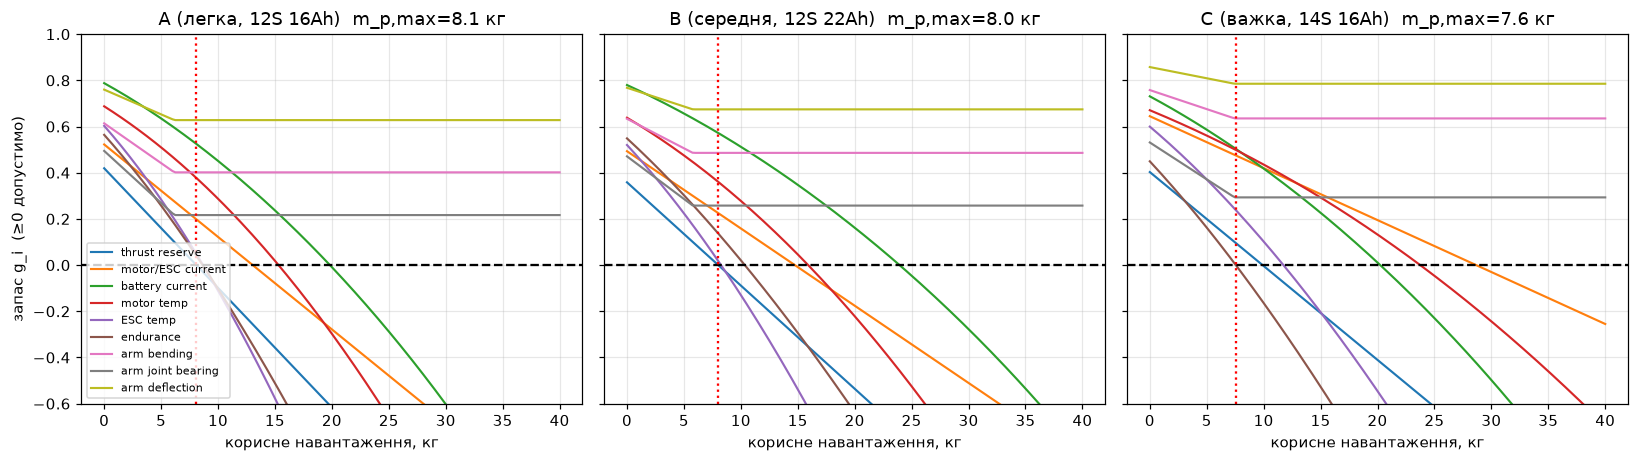

In [25]:
fig,ax=plt.subplots(1,3,figsize=(15,4.3),sharey=True)
for a,c in zip(ax,CFG):
    v,o=RES[c['name']]
    for i,n in enumerate(NAMES): a.plot(o['mg'],o['G'][i],label=n,lw=1.4)
    a.axhline(0,color='k',ls='--'); a.axvline(o['m_pmax'],color='r',ls=':')
    a.set_ylim(-0.6,1); a.set_title(f"{c['name']}  m_p,max={o['m_pmax']:.1f} кг"); a.set_xlabel('корисне навантаження, кг')
ax[0].set_ylabel('запас g_i  (≥0 допустимо)'); ax[0].legend(fontsize=7,loc='lower left'); plt.tight_layout(); savefig('g_curves'); plt.show()

**Як читати графік:** крива, що першою перетинає нуль, і є обмежувальним фактором. Обмеження 7–9 (вигин, зминання, прогин) не залежать від $m_p$ вище порога, бо розрахункова тяга обмежена $T_{max}$ двигуна. Тож за прийнятою моделлю **міцність променів не обмежує** (за статичного навантаження при максимальній тязі). Це висновок розрахункової моделі з гіпотетичними $\sigma_{all},E$; удар при посадці, втома та вібрації тут **не розглядалися**.

### Перевірка збіжності розв'язувача

Порівняння `brentq` і бісекції, а також збіжність по кроку сітки.

In [26]:
diff=[]
for c in CFG:
    v,o=RES[c['name']]; fin=np.isfinite(o['m_fz'])
    diff.append(dict(config=c['name'], max_abs_diff_кг=np.nanmax(np.abs(o['m_fz'][fin]-o['m_bi'][fin])), iter_бісекції=int(np.nanmax(o['it']))))
display(pd.DataFrame(diff).set_index('config'))
conv=pd.DataFrame({c['name']:[solve_payload(flatten(c['p']),m_max=40,ngrid=n)['m_pmax'] for n in (21,41,81,161,321)] for c in CFG},
                  index=[f'сітка {n}' for n in (21,41,81,161,321)])
display(conv.round(4))

,max_abs_diff_кг,iter_бісекції
config,,
"A (легка, 12S 16Ah)",4.178192e-07,18
"B (середня, 12S 22Ah)",4.432874e-07,18
"C (важка, 14S 16Ah)",4.597979e-07,18


,"A (легка, 12S 16Ah)","B (середня, 12S 22Ah)","C (важка, 14S 16Ah)"
сітка 21,8.0939,8.0179,7.5559
сітка 41,8.0939,8.0179,7.5559
сітка 81,8.0939,8.0179,7.5559
сітка 161,8.0939,8.0179,7.5559
сітка 321,8.0939,8.0179,7.5559


## 6. Чутливість (OAT, one-at-a-time)

Кожен змінний параметр по черзі ставиться в $\theta_{\min}$ і $\theta_{\max}$ при решті номінальних. Показано відхилення $m_{p,\max}$ від номіналу.

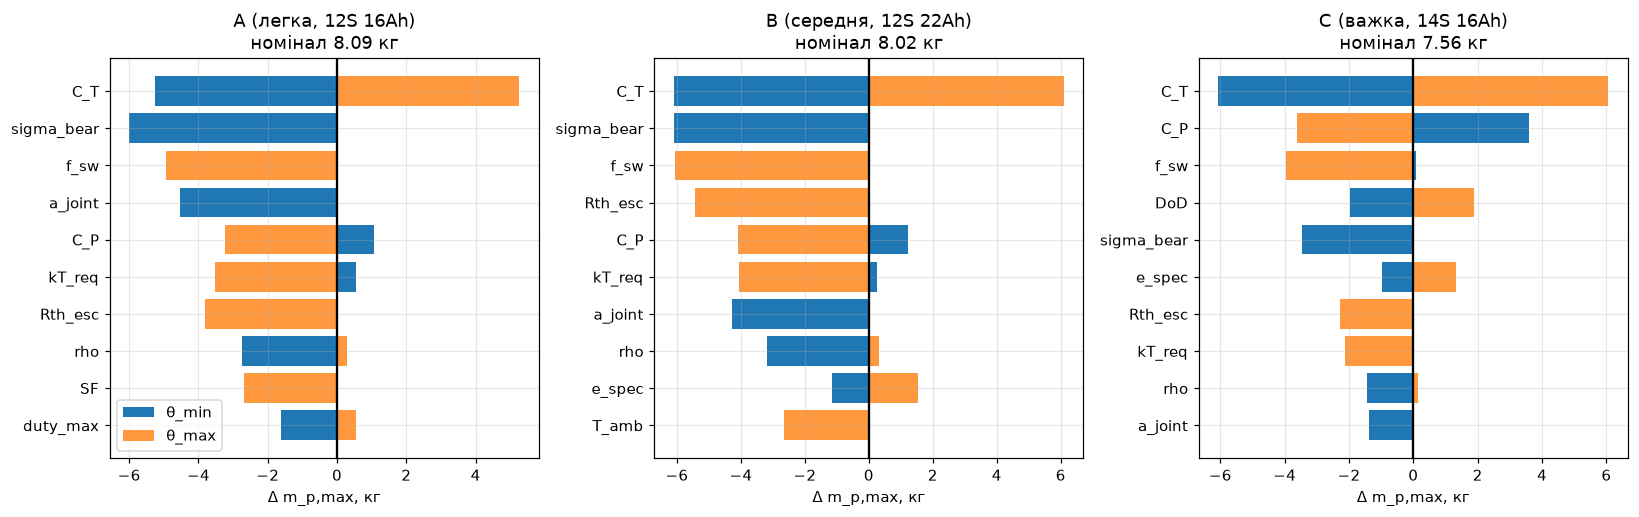

A (легка, 12S 16Ah)


,param,status,m_lo,m_hi,swing
0,C_T,hypothesis,2.83,13.36,10.53
1,sigma_bear,hypothesis,2.09,8.09,6.00
2,f_sw,hypothesis,8.09,3.15,4.94
3,a_joint,hypothesis,3.57,8.09,4.52
4,C_P,hypothesis,9.16,4.85,4.31
5,kT_req,requirement,8.64,4.58,4.06


B (середня, 12S 22Ah)


,param,status,m_lo,m_hi,swing
0,C_T,hypothesis,1.92,14.12,12.20
1,sigma_bear,hypothesis,1.92,8.02,6.10
2,f_sw,hypothesis,8.02,1.95,6.07
3,Rth_esc,hypothesis,8.02,2.58,5.44
4,C_P,hypothesis,9.24,3.91,5.33
5,kT_req,requirement,8.26,3.95,4.31


C (важка, 14S 16Ah)


,param,status,m_lo,m_hi,swing
0,C_T,hypothesis,1.49,13.62,12.13
1,C_P,hypothesis,11.15,3.95,7.20
2,f_sw,hypothesis,7.63,3.61,4.02
3,DoD,hypothesis,5.60,9.43,3.83
4,sigma_bear,hypothesis,4.10,7.56,3.45
5,e_spec,hypothesis,6.57,8.87,2.30


In [27]:
def oat(c):
    v0=flatten(c['p']); base=solve_payload(v0)['m_pmax']; out=[]
    for k,p in c['p'].items():
        if p.lo==p.hi: continue
        r=[solve_payload(flatten(c['p'],{k:val}))['m_pmax'] for val in (p.lo,p.hi)]
        out.append(dict(param=k,status=p.status,m_lo=r[0],m_hi=r[1],swing=abs(r[1]-r[0])))
    return base,pd.DataFrame(out).sort_values('swing',ascending=False).reset_index(drop=True)
OAT={c['name']:oat(c) for c in CFG}
fig,ax=plt.subplots(1,3,figsize=(15,4.8))
for a,c in zip(ax,CFG):
    base,df=OAT[c['name']]; d=df.head(10)[::-1]
    a.barh(d.param,d.m_lo-base,color='tab:blue',label='θ_min'); a.barh(d.param,d.m_hi-base,color='tab:orange',alpha=.8,label='θ_max')
    a.axvline(0,color='k'); a.set_title(f"{c['name']}\nномінал {base:.2f} кг"); a.set_xlabel('Δ m_p,max, кг')
ax[0].legend(); plt.tight_layout(); savefig('tornado'); plt.show()
for c in CFG:
    print(c['name']); display(OAT[c['name']][1].head(6).round(2))

## 7. Monte Carlo: діапазон невизначеності

Усі змінні параметри семплюються з **трикутного розподілу** $\mathrm{Tri}(\theta_{\min},\theta_{nom},\theta_{\max})$ (мода = номінал), незалежно. Це припущення про форму розподілу, а не результат вимірювань. $N=3000$ на конфігурацію, `seed=42`.

In [28]:
def monte_carlo(c, N=3000, seed=42):
    rng=np.random.default_rng(seed); var=[k for k,p in c['p'].items() if p.lo<p.hi]
    X=np.column_stack([rng.triangular(c['p'][k].lo,c['p'][k].value,c['p'][k].hi,N) for k in var])
    y=np.full(N,np.nan); lim=[None]*N
    for j in range(N):
        try:
            o=solve_payload(flatten(c['p'],dict(zip(var,X[j]))),m_max=30,ngrid=61); y[j]=o['m_pmax']; lim[j]=o['limiting']
        except Exception: pass
    return var,X,y,np.array(lim,dtype=object)
MC={c['name']:monte_carlo(c) for c in CFG}
rows=[]
for c in CFG:
    var,X,y,lim=MC[c['name']]; ok=np.isfinite(y)
    pos=ok&(y>0)
    rows.append(dict(config=c['name'],N_ok=int(ok.sum()),**{'P(m_p=0)':(y[ok]<=0).mean()},
                     P5=np.percentile(y[ok],5),P50=np.percentile(y[ok],50),P95=np.percentile(y[ok],95),
                     **{'P5|m>0':np.percentile(y[pos],5),'P50|m>0':np.percentile(y[pos],50),'P95|m>0':np.percentile(y[pos],95)},
                     **{'P(m_p≥5)':(y[ok]>=5).mean(),'P(m_p≥8)':(y[ok]>=8).mean()}))
MCT=pd.DataFrame(rows).set_index('config').round(2); display(MCT)

,N_ok,P(m_p=0),P5,P50,P95,P5|m>0,P50|m>0,P95|m>0,P(m_p≥5),P(m_p≥8)
config,,,,,,,,,,
"A (легка, 12S 16Ah)",3000,0.06,0.00,4.59,9.17,0.97,4.80,9.26,0.44,0.11
"B (середня, 12S 22Ah)",3000,0.13,0.00,3.85,9.45,0.61,4.44,9.71,0.37,0.11
"C (важка, 14S 16Ah)",3000,0.05,0.03,5.25,10.64,1.06,5.43,10.72,0.53,0.19


**Важливо для інтерпретації.** `P(m_p=0)` це частка вибірок, де обмеження порушене вже **без корисного навантаження**. Здебільшого це зминання стінки під болтами (`arm joint bearing`) за низького $\sigma_{bear}$: тобто конструкція не витримує повну тягу власних моторів. Це **дефект проєкту за цих параметрів**, а не вичерпання вантажопідйомності, тому нижній квантиль $P5=0$ слід читати разом зі стовпцями `P5|m>0 … P95|m>0` (умовні оцінки для життєздатних проєктів).

Номінальне значення (7.6–8.1 кг) лежить у **верхній** частині розподілу, а медіана MC помітно нижча. Причина: $m_{p,\max}$ це мінімум кількох невизначених обмежень, тому розкид параметрів зміщує результат вниз (ефект екстремальних значень), а багато діапазонів асиметричні в гірший бік.

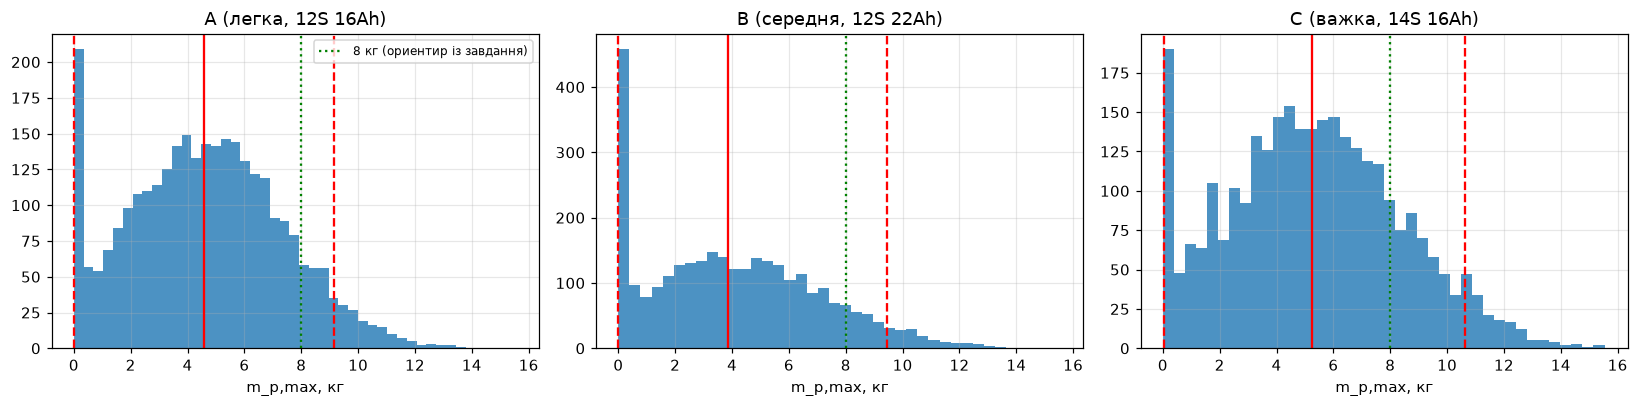

Частота обмежувального фактора в MC, %:


,"A (легка, 12S 16Ah)","B (середня, 12S 22Ah)","C (важка, 14S 16Ah)"
ESC temp,33.0,44.7,25.4
arm bending,0.5,0.0,0.0
arm joint bearing,19.4,13.9,11.0
endurance,6.2,0.9,42.0
motor temp,0.4,0.3,0.0
motor/ESC current,0.0,0.1,0.0
thrust reserve,40.6,40.0,21.6


In [29]:
fig,ax=plt.subplots(1,3,figsize=(15,3.8),sharex=True)
for a,c in zip(ax,CFG):
    var,X,y,lim=MC[c['name']]; ok=np.isfinite(y)
    a.hist(y[ok],bins=40,color='tab:blue',alpha=.8)
    for q,ls in ((5,'--'),(50,'-'),(95,'--')): a.axvline(np.percentile(y[ok],q),color='r',ls=ls)
    a.axvline(8,color='g',ls=':',label='8 кг (ориентир із завдання)'); a.set_title(c['name']); a.set_xlabel('m_p,max, кг')
ax[0].legend(fontsize=8); plt.tight_layout(); savefig('mc_hist'); plt.show()
print('Частота обмежувального фактора в MC, %:')
display(pd.DataFrame({c['name']:pd.Series(MC[c['name']][3]).value_counts(normalize=True)*100 for c in CFG}).fillna(0).round(1))

### Глобальна чутливість та збіжність Monte Carlo

Ранговий коефіцієнт Спірмена $\rho_s(\theta_k,m_{p,\max})$ показує, які параметри найбільше визначають розкид результату (враховує всі параметри одночасно, на відміну від OAT).

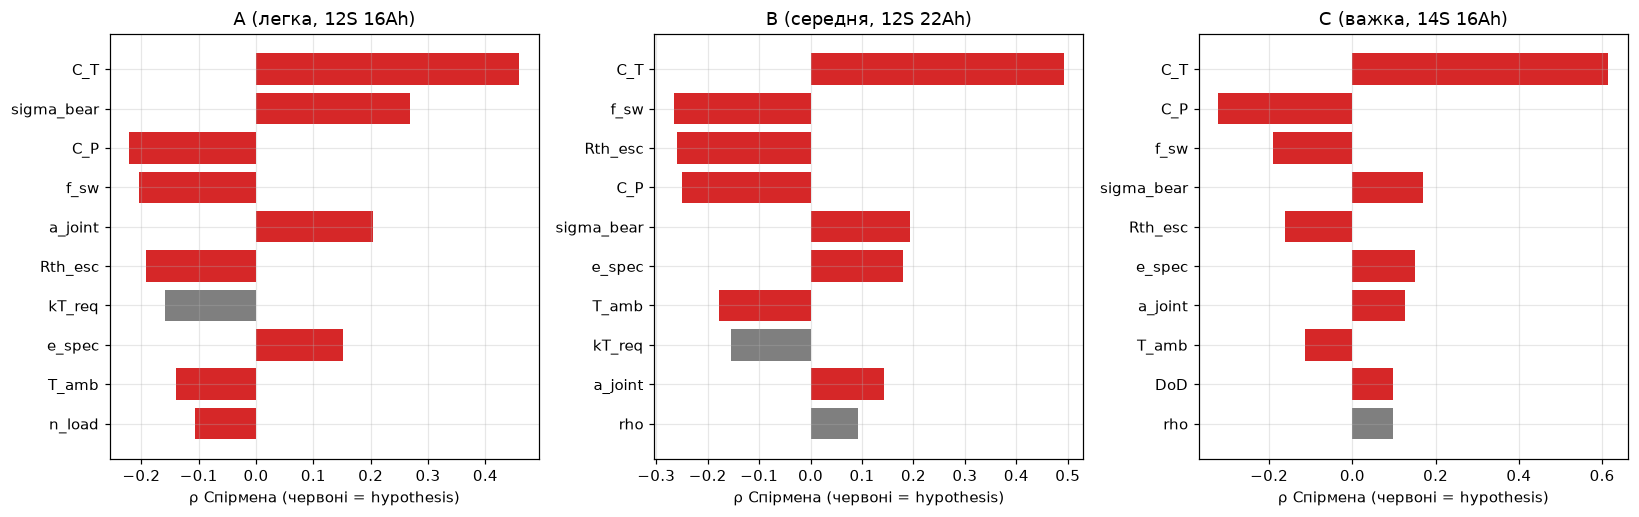

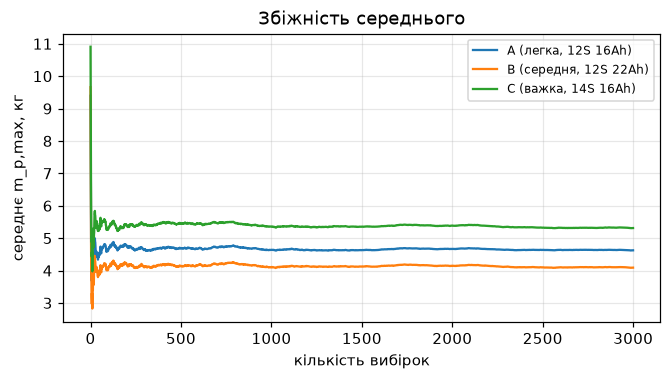

In [30]:
fig,ax=plt.subplots(1,3,figsize=(15,4.8)); SP={}
for a,c in zip(ax,CFG):
    var,X,y,lim=MC[c['name']]; ok=np.isfinite(y)
    rho=pd.Series({k:spearmanr(X[ok,i],y[ok])[0] for i,k in enumerate(var)}).dropna(); SP[c['name']]=rho
    t=rho.reindex(rho.abs().sort_values(ascending=False).index).head(10)[::-1]
    a.barh(t.index,t.values,color=['tab:red' if c['p'][k].status=='hypothesis' else 'tab:gray' for k in t.index])
    a.set_title(c['name']); a.set_xlabel('ρ Спірмена (червоні = hypothesis)')
plt.tight_layout(); savefig('spearman'); plt.show()
fig,ax=plt.subplots(figsize=(7,3.4))
for c in CFG:
    y=MC[c['name']][2]; y=y[np.isfinite(y)]; ax.plot(np.cumsum(y)/np.arange(1,len(y)+1),label=c['name'])
ax.set_xlabel('кількість вибірок'); ax.set_ylabel('середнє m_p,max, кг'); ax.set_title('Збіжність середнього'); ax.legend(fontsize=8); savefig('mc_convergence'); plt.show()

## 8. Модуль оцінювання достовірності

Автоматично: (а) перевіряє внутрішні сценарії і суперечності допущень, (б) знаходить параметри, що домінують у невизначеності, і чи вони лише гіпотези, (в) розділяє результати за статусом, (г) формує текстовий звіт.

In [31]:
def audit(c):
    v,o=RES[c['name']]; g,d=constraints(v,o['m_pmax'],o['rm']); w=[]; checks=[]
    r,m,rm=d['r'],d['m'],d['rm']
    checks.append(('Баланс тяги 4T = m g', abs(v['N']*r['T']-m['total']*v['g'])<1e-6))
    checks.append(('P_in ≥ P_вал (енергія)', r['Pin']>=r['Psh']))
    checks.append(('FoM у діапазоні 0.4–0.75', 0.4<=r['FoM']<=0.75))
    checks.append(('Збіг brentq/бісекція < 1e-4 кг', np.nanmax(np.abs(o['m_fz'][np.isfinite(o['m_fz'])]-o['m_bi'][np.isfinite(o['m_bi'])]))<1e-4))
    checks.append(('Шпаруватість у висінні < 0.85', r['duty']<0.85))
    checks.append(('Розмірності (pint) і збіг з unit-aware формулами', DIM_OK[c['name']]))
    Imax=rm['kQ']*rm['n_max']**2/rm['Kt']+v['I0']
    if v['N']*Imax>v['C_cont']*v['Cap']: w.append(f"пікове споживання {v['N']*Imax:.0f} А > довготривалого C-рейтингу {v['C_cont']*v['Cap']:.0f} А (допустимо лише короткочасно)")
    if Imax>min(v['I_cont_m'],v['I_cont_esc']): w.append(f"струм при макс. тязі {Imax:.0f} А > довготривалого рейтингу мотора/ESC (допустимо лише як пік)")
    if rm['lim']=='current': w.append('максимальна тяга обмежена струмом, а не напругою')
    if np.isinf(o['m_fz'][6:]).all(): w.append('механіка не обмежує: результат визначають електрика/тяга/час (див. застереження про навантаження)')
    return checks,w
txt=['# Автоматичний звіт достовірності\n']
for c in CFG:
    checks,w=audit(c); var,X,y,lim=MC[c['name']]; ok=np.isfinite(y); rho=SP[c['name']]
    top=rho.reindex(rho.abs().sort_values(ascending=False).index).head(5)
    nh=sum(p.status=='hypothesis' for p in c['p'].values()); nv=sum(p.status=='verified' for p in c['p'].values()); nr=sum(p.status=='requirement' for p in c['p'].values())
    hyp_top=[k for k in top.index if c['p'][k].status=='hypothesis']
    base=OAT[c['name']][0]
    txt.append(f"## {c['name']}")
    txt.append(f"- **Розрахункова оцінка (номінал):** {base:.1f} кг, обмежує: *{RES[c['name']][1]['limiting']}*")
    txt.append(f"- **Діапазон невизначеності Monte Carlo (P5–P95):** {np.percentile(y[ok],5):.1f} – {np.percentile(y[ok],95):.1f} кг, медіана {np.percentile(y[ok],50):.1f} кг")
    txt.append(f"- **Частка вибірок з m_p=0 (конструкція/режим недопустимі без вантажу):** {(y[ok]<=0).mean()*100:.0f}%; для решти P5–P95 = {np.percentile(y[ok&(y>0)],5):.1f} – {np.percentile(y[ok&(y>0)],95):.1f} кг")
    txt.append(f"- **Склад параметрів:** verified {nv}, requirement {nr}, hypothesis {nh}. Експериментально підтверджених: 0")
    txt.append(f"- **Домінують у невизначеності:** " + ', '.join(f"`{k}` (ρ={top[k]:+.2f}, {c['p'][k].status})" for k in top.index))
    txt.append(f"- **З них гіпотези:** {len(hyp_top)} з {len(top)} → результат **не можна вважати підтвердженим** без вимірювання цих величин")
    txt.append("- **Внутрішні перевірки:** " + '; '.join(f"{'✔' if ok_ else '✘'} {n}" for n,ok_ in checks))
    txt.append("- **Попередження / суперечності:** " + ('; '.join(w) if w else 'не виявлено'))
    txt.append("")
txt.append('''## Класифікація результатів
| Клас | Що сюди входить |
|---|---|
| Підтверджено експериментом | немає |
| Розрахункові оцінки | m_p,max (номінал), діапазон P5–P95, обмежувальний фактор, ранжування чутливості |
| Гіпотези | C_T, C_P, Kv, R_m, I_0, R_pack, e_spec, теплові опори, σ_all, E, n_load та ін. (статус `hypothesis`) |''')
display(Markdown('\n'.join(txt)))

# Автоматичний звіт достовірності

## A (легка, 12S 16Ah)
- **Розрахункова оцінка (номінал):** 8.1 кг, обмежує: *thrust reserve*
- **Діапазон невизначеності Monte Carlo (P5–P95):** 0.0 – 9.2 кг, медіана 4.6 кг
- **Частка вибірок з m_p=0 (конструкція/режим недопустимі без вантажу):** 6%; для решти P5–P95 = 1.0 – 9.3 кг
- **Склад параметрів:** verified 12, requirement 4, hypothesis 35. Експериментально підтверджених: 0
- **Домінують у невизначеності:** `C_T` (ρ=+0.46, hypothesis), `sigma_bear` (ρ=+0.27, hypothesis), `C_P` (ρ=-0.22, hypothesis), `f_sw` (ρ=-0.20, hypothesis), `a_joint` (ρ=+0.20, hypothesis)
- **З них гіпотези:** 5 з 5 → результат **не можна вважати підтвердженим** без вимірювання цих величин
- **Внутрішні перевірки:** ✔ Баланс тяги 4T = m g; ✔ P_in ≥ P_вал (енергія); ✔ FoM у діапазоні 0.4–0.75; ✔ Збіг brentq/бісекція < 1e-4 кг; ✔ Шпаруватість у висінні < 0.85; ✔ Розмірності (pint) і збіг з unit-aware формулами
- **Попередження / суперечності:** пікове споживання 199 А > довготривалого C-рейтингу 160 А (допустимо лише короткочасно); струм при макс. тязі 50 А > довготривалого рейтингу мотора/ESC (допустимо лише як пік); механіка не обмежує: результат визначають електрика/тяга/час (див. застереження про навантаження)

## B (середня, 12S 22Ah)
- **Розрахункова оцінка (номінал):** 8.0 кг, обмежує: *thrust reserve*
- **Діапазон невизначеності Monte Carlo (P5–P95):** 0.0 – 9.4 кг, медіана 3.8 кг
- **Частка вибірок з m_p=0 (конструкція/режим недопустимі без вантажу):** 13%; для решти P5–P95 = 0.6 – 9.7 кг
- **Склад параметрів:** verified 12, requirement 4, hypothesis 35. Експериментально підтверджених: 0
- **Домінують у невизначеності:** `C_T` (ρ=+0.49, hypothesis), `f_sw` (ρ=-0.27, hypothesis), `Rth_esc` (ρ=-0.26, hypothesis), `C_P` (ρ=-0.25, hypothesis), `sigma_bear` (ρ=+0.19, hypothesis)
- **З них гіпотези:** 5 з 5 → результат **не можна вважати підтвердженим** без вимірювання цих величин
- **Внутрішні перевірки:** ✔ Баланс тяги 4T = m g; ✔ P_in ≥ P_вал (енергія); ✔ FoM у діапазоні 0.4–0.75; ✔ Збіг brentq/бісекція < 1e-4 кг; ✔ Шпаруватість у висінні < 0.85; ✔ Розмірності (pint) і збіг з unit-aware формулами
- **Попередження / суперечності:** пікове споживання 247 А > довготривалого C-рейтингу 220 А (допустимо лише короткочасно); струм при макс. тязі 62 А > довготривалого рейтингу мотора/ESC (допустимо лише як пік); механіка не обмежує: результат визначають електрика/тяга/час (див. застереження про навантаження)

## C (важка, 14S 16Ah)
- **Розрахункова оцінка (номінал):** 7.6 кг, обмежує: *endurance*
- **Діапазон невизначеності Monte Carlo (P5–P95):** 0.0 – 10.6 кг, медіана 5.2 кг
- **Частка вибірок з m_p=0 (конструкція/режим недопустимі без вантажу):** 5%; для решти P5–P95 = 1.1 – 10.7 кг
- **Склад параметрів:** verified 12, requirement 4, hypothesis 35. Експериментально підтверджених: 0
- **Домінують у невизначеності:** `C_T` (ρ=+0.62, hypothesis), `C_P` (ρ=-0.32, hypothesis), `f_sw` (ρ=-0.19, hypothesis), `sigma_bear` (ρ=+0.17, hypothesis), `Rth_esc` (ρ=-0.16, hypothesis)
- **З них гіпотези:** 5 з 5 → результат **не можна вважати підтвердженим** без вимірювання цих величин
- **Внутрішні перевірки:** ✔ Баланс тяги 4T = m g; ✔ P_in ≥ P_вал (енергія); ✔ FoM у діапазоні 0.4–0.75; ✔ Збіг brentq/бісекція < 1e-4 кг; ✔ Шпаруватість у висінні < 0.85; ✔ Розмірності (pint) і збіг з unit-aware формулами
- **Попередження / суперечності:** пікове споживання 245 А > довготривалого C-рейтингу 160 А (допустимо лише короткочасно); струм при макс. тязі 61 А > довготривалого рейтингу мотора/ESC (допустимо лише як пік); механіка не обмежує: результат визначають електрика/тяга/час (див. застереження про навантаження)

## Класифікація результатів
| Клас | Що сюди входить |
|---|---|
| Підтверджено експериментом | немає |
| Розрахункові оцінки | m_p,max (номінал), діапазон P5–P95, обмежувальний фактор, ранжування чутливості |
| Гіпотези | C_T, C_P, Kv, R_m, I_0, R_pack, e_spec, теплові опори, σ_all, E, n_load та ін. (статус `hypothesis`) |

### 8.2 Припущення та граничні умови

Зведений перелік допущень (кожне має наслідок для достовірності) і область застосовності моделі. Цей перелік автоматично потрапляє до технічного звіту.


In [32]:
ASSUMPTIONS = [
 ('A1','Аеродинаміка','Стаціонарне висіння; C_T, C_P сталі, T=k_T n², Q=k_Q n²','Не враховано швидкість польоту, ефект землі, взаємодію гвинтів, число Рейнольдса'),
 ('A2','Аеродинаміка','Імпульсна теорія + FoM як контроль; BEMT не застосовано','C_T, C_P залишаються гіпотезами до стендового тесту'),
 ('A3','Мотор','Лінійна DC-модель: K_t=60/(2πK_v), стале R_m, стале I_0','Немає насичення, немає залежності R_m від температури'),
 ('A4','ESC','Втрати P_esc = R_on·I² + f_sw·P_in; макс. шпаруватість 0.95','Спрощена модель комутації; значення гіпотетичні'),
 ('A5','Батарея','Стала EMF S·3.7 В, стале R_pack; корисна енергія = S·V_c·Cap·DoD','Без залежності від SoC і температури, без ефекту Пейкерта'),
 ('A6','Тепло','Стаціонарно: ΔT = P_втрат·R_th, R_th сталий (обдув гвинта)','Не враховано нагрів у часі та вплив температури зовнішнього повітря на R_th'),
 ('A7','Маса','Вузол мотор+ESC+гвинт на кінці променя; центральне тіло як куля; ЦМ у центрі','Зсув ЦМ від вантажу не враховано; інерція наближена'),
 ('A8','Механіка','Промінь = консоль; сила T_d=min(n_load·m·g/N, T_max) + реактивний момент; ізотропний матеріал E_eff','Немає удару, втоми, вібрацій, власних частот, втрати стійкості'),
 ('A9','Механіка','Стик: пара болтів, момент як пара сил, зминання стінки труби','Не розглядається зріз болта, відшарування, дефекти укладки'),
 ('A10','Невизначеність','Параметри незалежні, трикутні розподіли [min, номінал, max]','Діапазони експертні, не з вимірювань; кореляції (K_v–R_m) не враховано'),
 ('A11','Вимоги','t_req = 10 хв, k_T = 1.8, SF = 1.5 (вимоги місії)','ЗАДАЄТЬСЯ ЗАМОВНИКОМ; зміна вимог змінює обмежувальний фактор'),
 ('A12','Середовище','ISA на рівні моря (ρ=1.225, діапазон 1.0–1.25), T_amb=25 °C (−10…40), без вітру','Спека/висота зменшують тягу і запас'),
 ('A13','Розв’язок','m_p,max = min m_i*; залежність від m через повну масу; перше порушення на сітці','Обмеження незалежні; теплова взаємодія мотор↔батарея спрощена'),
 ('A14','Корисне навантаження','Точкова маса в центрі, без зсуву ЦМ','Реальне розташування вантажу змінює моменти і керованість (не оцінено)'),
]
BOUNDS = [
 ('Корисне навантаження m_p','0 – 40 кг (сітка 161 точка)','вище не досліджується'),
 ('Режим','стаціонарне висіння','маневр лише через n_load у механіці'),
 ('Геометрія','4 ротори, X-схема, D = 22″ = 0.5588 м','фіксовано завданням'),
 ('Живлення','12S або 14S, ємність 16–22 Аг','задано конфігураціями A, B, C'),
 ('Щільність повітря','1.0 – 1.25 кг/м³','рівень моря … спека/висота ≈ 2 км'),
 ('Температура середовища','−10 … 40 °C','вплив на батарею не моделюється'),
 ('Промінь (механіка)','затиснутий у центрі, сила на вільному кінці','без контакту із землею'),
 ('Monte Carlo','N = 3000 (1500 у сценаріях), seed = 42','трикутні незалежні розподіли'),
]
display(pd.DataFrame(ASSUMPTIONS,columns=['№','Область','Припущення','Наслідок / обмеження']).set_index('№'))
display(pd.DataFrame(BOUNDS,columns=['Величина','Діапазон / умова','Примітка']).set_index('Величина'))


,Область,Припущення,Наслідок / обмеження
№,,,
A1,Аеродинаміка,"Стаціонарне висіння; C_T, C_P сталі, T=k_T n²,...","Не враховано швидкість польоту, ефект землі, в..."
A2,Аеродинаміка,Імпульсна теорія + FoM як контроль; BEMT не за...,"C_T, C_P залишаються гіпотезами до стендового ..."
A3,Мотор,"Лінійна DC-модель: K_t=60/(2πK_v), стале R_m, ...","Немає насичення, немає залежності R_m від темп..."
A4,ESC,Втрати P_esc = R_on·I² + f_sw·P_in; макс. шпар...,Спрощена модель комутації; значення гіпотетичні
A5,Батарея,"Стала EMF S·3.7 В, стале R_pack; корисна енерг...","Без залежності від SoC і температури, без ефек..."
A6,Тепло,"Стаціонарно: ΔT = P_втрат·R_th, R_th сталий (о...",Не враховано нагрів у часі та вплив температур...
A7,Маса,Вузол мотор+ESC+гвинт на кінці променя; центра...,Зсув ЦМ від вантажу не враховано; інерція набл...
A8,Механіка,"Промінь = консоль; сила T_d=min(n_load·m·g/N, ...","Немає удару, втоми, вібрацій, власних частот, ..."
A9,Механіка,"Стик: пара болтів, момент як пара сил, зминанн...","Не розглядається зріз болта, відшарування, деф..."


,Діапазон / умова,Примітка
Величина,,
Корисне навантаження m_p,0 – 40 кг (сітка 161 точка),вище не досліджується
Режим,стаціонарне висіння,маневр лише через n_load у механіці
Геометрія,"4 ротори, X-схема, D = 22″ = 0.5588 м",фіксовано завданням
Живлення,"12S або 14S, ємність 16–22 Аг","задано конфігураціями A, B, C"
Щільність повітря,1.0 – 1.25 кг/м³,рівень моря … спека/висота ≈ 2 км
Температура середовища,−10 … 40 °C,вплив на батарею не моделюється
Промінь (механіка),"затиснутий у центрі, сила на вільному кінці",без контакту із землею
Monte Carlo,"N = 3000 (1500 у сценаріях), seed = 42",трикутні незалежні розподіли


### 8.3 Що дасть вимірювання: звуження діапазону невизначеності

Щоб сформулювати **умови достовірності**, потрібно знати, наскільки результат поліпшиться після експериментів. Для цього параметри з експериментальних груп послідовно «вимірюються», тобто їхній діапазон звужується до вказаної відносної похибки (при тому самому номіналі), і Monte Carlo повторюється ($N=1500$). Це оцінка *потенційного* ефекту, а не результат вимірювань.

| Сценарій | Що вимірюємо (відносна похибка) |
|---|---|
| S1 | стенд гвинта і мотора: $C_T,C_P$ ±5%, $K_v$ ±3%, $R_m$ ±5%, $I_0$ ±10% |
| S2 | + ESC і тепло: $f_{sw},R_{on},R_{th,esc},R_{th,m}$ ±10% |
| S3 | + батарея: $e_{spec},DoD$ ±5%, $R_{pack}$ ±10% |
| S4 | + стик і матеріал: $\sigma_{bear},\sigma_{all},E$ ±8%, $a_{joint}$ ±3% |


P5               P50               P95               \
конфігурація           A     B     C     A     B     C     A     B      C   
сценарій                                                                    
S0 зараз            0.00  0.00  0.00  4.56  3.89  5.18  9.19  9.47  10.28   
S1 + стенд          0.32  0.00  1.10  5.33  4.63  6.24  8.41  8.50   8.62   
S2 + ESC/тепло      0.49  0.20  2.66  6.12  5.87  6.79  8.62  8.93   8.80   
S3 + батарея        0.49  0.00  2.29  5.99  5.68  6.68  8.49  8.63   8.20   
S4 + стик/матеріал  3.41  3.02  4.61  6.28  5.97  6.82  8.49  8.75   8.24   

                   (P95−P5)/P50              
конфігурація                  A     B     C  
сценарій                                     
S0 зараз                   2.02  2.43  1.99  
S1 + стенд                 1.52  1.84  1.21  
S2 + ESC/тепло             1.33  1.49  0.90  
S3 + батарея               1.34  1.52  0.89  
S4 + стик/матеріал         0.81  0.96  0.53

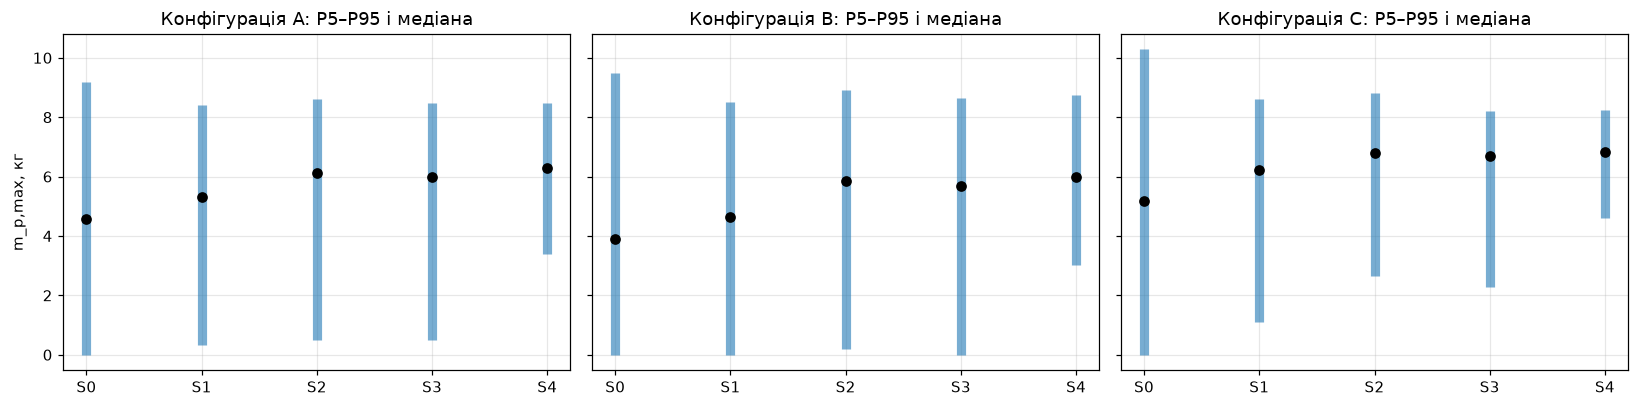

In [33]:
from dataclasses import replace
SCEN = [('S0 зараз',{}),
        ('S1 + стенд',{'C_T':.05,'C_P':.05,'Kv':.03,'Rm':.05,'I0':.10}),
        ('S2 + ESC/тепло',{'f_sw':.10,'R_on':.10,'Rth_esc':.10,'Rth_m':.10}),
        ('S3 + батарея',{'e_spec':.05,'DoD':.05,'R_pack':.10}),
        ('S4 + стик/матеріал',{'sigma_bear':.08,'a_joint':.03,'sigma_all':.08,'E':.08})]
def narrowed(c, spec):
    p={}
    for k,x in c['p'].items():
        if k in spec and x.lo<x.hi:
            d=spec[k]; p[k]=replace(x, lo=max(x.lo,x.value*(1-d)), hi=min(x.hi,x.value*(1+d)))
        else: p[k]=x
    return dict(name=c['name'],p=p)
cum={}; rows=[]
for sname,spec in SCEN:
    cum.update(spec)
    for c in CFG:
        var,X,y,lim=monte_carlo(narrowed(c,cum),N=1500); ok=np.isfinite(y); pos=ok&(y>0)
        p5,p50,p95=np.percentile(y[ok],[5,50,95])
        rows.append(dict(сценарій=sname,конфігурація=c['name'][:1],P5=p5,P50=p50,P95=p95,
                         **{'(P95−P5)/P50':(p95-p5)/p50,'P(m_p=0)':(y[ok]<=0).mean()}))
VOI_T=pd.DataFrame(rows)
display(VOI_T.pivot(index='сценарій',columns='конфігурація',values=['P5','P50','P95','(P95−P5)/P50']).reindex([s for s,_ in SCEN]).round(2))
fig,ax=plt.subplots(1,3,figsize=(15,3.8),sharey=True)
for a,cn in zip(ax,'ABC'):
    d=VOI_T[VOI_T.конфігурація==cn].reset_index(drop=True)
    a.vlines(range(len(d)),d.P5,d.P95,lw=6,color='tab:blue',alpha=.6); a.plot(range(len(d)),d.P50,'ko')
    a.set_xticks(range(len(d))); a.set_xticklabels([s.split()[0] for s in d.сценарій]); a.set_title(f'Конфігурація {cn}: P5–P95 і медіана')
ax[0].set_ylabel('m_p,max, кг'); plt.tight_layout(); savefig('voi'); plt.show()


### 8.4 Умови, за яких результат можна вважати достовірним

Результат $m_{p,\max}$ вважається **достовірним** лише коли виконано **всі** критерії K1–K5. Порогові значення (зокрема K2) є пропозицією і мають бути узгоджені із замовником.

| № | Критерій |
|---|---|
| K1 | усі 5 параметрів з найбільшою чутливістю (за $\lvert\rho_s\rvert$) мають статус `verified` (виміряні) |
| K2 | відносна ширина діапазону $(P95-P5)/P50\le 0.5$ |
| K3 | усі внутрішні перевірки (баланс тяги, енергія, FoM, збіг методів, шпаруватість) пройдені |
| K4 | перевірка розмірностей пройдена, модель збігається з unit-aware формулами |
| K5 | розбіжність модель/стенд ≤ 10% за тягою, потужністю і часом висіння (потребує експерименту) |


In [34]:
CRIT=[]
for c in CFG:
    n=c['name']; rho=SP[n]; top=rho.reindex(rho.abs().sort_values(ascending=False).index).head(5)
    nver=sum(c['p'][k].status=='verified' for k in top.index)
    v0=VOI_T[(VOI_T.конфігурація==n[:1])&(VOI_T.сценарій=='S0 зараз')].iloc[0]['(P95−P5)/P50']
    v4=VOI_T[(VOI_T.конфігурація==n[:1])&(VOI_T.сценарій=='S4 + стик/матеріал')].iloc[0]['(P95−P5)/P50']
    checks,w=audit(c); k3=all(ok_ for nm,ok_ in checks if not nm.startswith('Розмірності'))
    st=[nver==5, v0<=0.5, k3, DIM_OK[n] and DIM_NEG, False]
    CRIT.append(dict(конфігурація=n,
        K1=f"{'✔' if st[0] else '✘'} ({nver}/5 виміряно)",
        K2=f"{'✔' if st[1] else '✘'} зараз {v0:.2f}; після S4 {v4:.2f}" ,
        K3='✔' if st[2] else '✘', K4='✔' if st[3] else '✘', K5='✘ немає стендових даних',
        verdict='ДОСТОВІРНИЙ' if all(st) else f'НЕ підтверджений ({sum(st)}/5 критеріїв)'))
CRIT_T=pd.DataFrame(CRIT).set_index('конфігурація'); display(CRIT_T)


,K1,K2,K3,K4,K5,verdict
конфігурація,,,,,,
"A (легка, 12S 16Ah)",✘ (0/5 виміряно),✘ зараз 2.02; після S4 0.81,✔,✔,✘ немає стендових даних,НЕ підтверджений (2/5 критеріїв)
"B (середня, 12S 22Ah)",✘ (0/5 виміряно),✘ зараз 2.43; після S4 0.96,✔,✔,✘ немає стендових даних,НЕ підтверджений (2/5 критеріїв)
"C (важка, 14S 16Ah)",✘ (0/5 виміряно),✘ зараз 1.99; після S4 0.53,✔,✔,✘ немає стендових даних,НЕ підтверджений (2/5 критеріїв)


## 9. Дані для експериментальної верифікації та межі моделі

**Експерименти (у порядку впливу на невизначеність) і критерії прийнятності:**

| № | Експеримент | Параметри, що уточнюються | Критерій прийнятності |
|---|---|---|---|
| 1 | Стенд: тяга, потужність, обороти, струм (мотор + 22″ гвинт + ESC, кілька напруг) | $C_T$, $C_P$, $K_v$, $R_m$, $I_0$, $T_{max}$ | $C_T$, $C_P$ ±5%, $K_v$ ±3%; збіг $T$ і $P_{el}$ з моделлю ≤ 10% у діапазоні 50–100% газу |
| 2 | Розрядна крива батареї під навантаженням | $R_{pack}$, $e_{spec}$, $DoD$ | $R_{pack}$ ±10%, використана енергія ±5% |
| 3 | Тепловий тест висіння з вантажем (термопара, тепловізор) | $R_{th,m}$, $R_{th,esc}$, $f_{sw}$, $R_{on}$ | $R_{th}$ ±10%; пікова температура модель/вимір ≤ 10 К |
| 4 | Статичний тест променя і стику до 1.5·$T_{max}$ (тензодатчики, прогин) | $E$, $\sigma_{all}$, $\sigma_{bear}$, $a_{joint}$ | $E$ ±8%, $\sigma_{bear}$ ±8%; прогин модель/вимір ≤ 15% |
| 5 | Зважування компонентів, положення ЦМ | $m_{motor}$, $m_{esc}$, $m_{prop}$, $m_{plate}$, $m_{av}$, $m_{misc}$ | маса ±2%, ЦМ ±5 мм |
| 6 | Підтвердження: висіння з $m_p=0.8\,m_{p,\max}$ | час, струм, температури | час висіння ±10% від моделі, без перегріву |

**Межі достовірності моделі:**

- Імпульсна теорія зі стаціонарними $C_T,C_P$: без впливу швидкості польоту, взаємодії гвинтів, ефекту землі.
- Мотор: лінійна DC-модель; ESC: спрощені втрати; батарея: постійний опір без залежності від SoC і температури.
- Механіка: статична консоль при максимальній тязі; **не враховано** удар, втому, вібрації, власні частоти, втрату стійкості, центральну пластину і шасі.
- Monte Carlo: незалежні трикутні розподіли з експертними діапазонами; кореляції не враховано.
- Вимога часу висіння $t_{req}=10$ хв задана умовно.
- Перевірка розмірностей охоплює формули моделі, але не гарантує правильності самих фізичних припущень.

**Не реалізовано (можливі наступні кроки):** BEMT для пропелера, МСЕ для вузла кріплення, варіація геометрії променя, обмеження керованості (запас моменту), власні частоти, кореляції параметрів, індекси Соболя.


## 10. Автоматична генерація технічного звіту

Комірка нижче збирає звіт із результатів цього ноутбука (таблиці, графіки, критерії, припущення) у `report/technical_report.md` і, якщо в системі є `pandoc` та `xelatex`, у PDF та HTML. Звіт розділяє **підтверджене / розрахункове / гіпотези**.


In [35]:
EXP_MD = '\n**Експерименти (у порядку впливу на невизначеність) і критерії прийнятності:**\n\n| № | Експеримент | Параметри, що уточнюються | Критерій прийнятності |\n|---|---|---|---|\n| 1 | Стенд: тяга, потужність, обороти, струм (мотор + 22″ гвинт + ESC, кілька напруг) | $C_T$, $C_P$, $K_v$, $R_m$, $I_0$, $T_{max}$ | $C_T$, $C_P$ ±5%, $K_v$ ±3%; збіг $T$ і $P_{el}$ з моделлю ≤ 10% у діапазоні 50–100% газу |\n| 2 | Розрядна крива батареї під навантаженням | $R_{pack}$, $e_{spec}$, $DoD$ | $R_{pack}$ ±10%, використана енергія ±5% |\n| 3 | Тепловий тест висіння з вантажем (термопара, тепловізор) | $R_{th,m}$, $R_{th,esc}$, $f_{sw}$, $R_{on}$ | $R_{th}$ ±10%; пікова температура модель/вимір ≤ 10 К |\n| 4 | Статичний тест променя і стику до 1.5·$T_{max}$ (тензодатчики, прогин) | $E$, $\\sigma_{all}$, $\\sigma_{bear}$, $a_{joint}$ | $E$ ±8%, $\\sigma_{bear}$ ±8%; прогин модель/вимір ≤ 15% |\n| 5 | Зважування компонентів, положення ЦМ | $m_{motor}$, $m_{esc}$, $m_{prop}$, $m_{plate}$, $m_{av}$, $m_{misc}$ | маса ±2%, ЦМ ±5 мм |\n| 6 | Підтвердження: висіння з $m_p=0.8\\,m_{p,\\max}$ | час, струм, температури | час висіння ±10% від моделі, без перегріву |\n\n**Межі достовірності моделі:**\n\n- Імпульсна теорія зі стаціонарними $C_T,C_P$: без впливу швидкості польоту, взаємодії гвинтів, ефекту землі.\n- Мотор: лінійна DC-модель; ESC: спрощені втрати; батарея: постійний опір без залежності від SoC і температури.\n- Механіка: статична консоль при максимальній тязі; **не враховано** удар, втому, вібрації, власні частоти, втрату стійкості, центральну пластину і шасі.\n- Monte Carlo: незалежні трикутні розподіли з експертними діапазонами; кореляції не враховано.\n- Вимога часу висіння $t_{req}=10$ хв задана умовно.\n- Перевірка розмірностей охоплює формули моделі, але не гарантує правильності самих фізичних припущень.\n\n**Не реалізовано (можливі наступні кроки):** BEMT для пропелера, МСЕ для вузла кріплення, варіація геометрії променя, обмеження керованості (запас моменту), власні частоти, кореляції параметрів, індекси Соболя.\n'
import subprocess, shutil, datetime
def md_table(df, index=True, widths=None):
    d=df.reset_index() if index else df; cols=list(d.columns)
    def f(x):
        if isinstance(x,(float,np.floating)):
            return '∞' if np.isinf(x) else ('—' if np.isnan(x) else f'{x:.2f}')
        return str(x).replace('|','/').replace('\n',' ')
    w=widths or [10]*len(cols)
    out=['| '+' | '.join(map(str,cols))+' |','|'+'|'.join('-'*max(3,int(x)) for x in w)+'|']
    out+=['| '+' | '.join(f(x) for x in r)+' |' for r in d.itertuples(index=False)]
    return '\n'.join(out)

R=[]; add=R.append
add(f"""---
title: "Технічний звіт: максимальне корисне навантаження квадрокоптера 4×22″"
subtitle: "Параметрична модель, чутливість, невизначеність, оцінка достовірності"
date: "{datetime.date.today().isoformat()}"
---
""")
add("""## 1. Мета і постановка задачі

Визначити максимально допустиме додаткове корисне навантаження $m_{p,\\max}$ квадрокоптера з чотирма двигунами та пропелерами 22″ за сукупністю механічних, енергетичних, теплових і експлуатаційних обмежень. Вихідних даних не надано, тому всі вхідні величини задані як параметри з діапазонами та статусами `verified` / `requirement` / `hypothesis`. Розглянуто три референсні конфігурації (A легка, B середня, C важка).

Допустимість задається безрозмірними запасами $g_i=1-\\text{попит}_i/\\text{ресурс}_i\\ge 0$ ($i=1\\ldots 9$), а граничне навантаження

$$m_{p,\\max}=\\min_i m_i^*,\\qquad g_i(m_i^*,\\theta)=0 .$$

Обмеження: запас тяги, струм мотора/ESC, струм батареї, температура мотора, температура ESC, час висіння, вигин променя, зминання під болтами, прогин променя.
""")
add("## 2. Припущення та граничні умови\n")
add(md_table(pd.DataFrame(ASSUMPTIONS,columns=['№','Область','Припущення','Наслідок']),index=False,widths=[4,12,40,40]))
add("\n**Область застосовності**\n")
add(md_table(pd.DataFrame(BOUNDS,columns=['Величина','Діапазон / умова','Примітка']),index=False,widths=[22,36,30]))
add("""
## 3. Модель

Маса: $m_{arm}=\\rho_{cf}\\tfrac{\\pi}{4}(d_o^2-d_i^2)L$, $m_{batt}=S V_c Cap/e_{spec}$. Пропелер: $T=k_Tn^2$, $Q=k_Qn^2$, $k_T=C_T\\rho D^4$, $k_Q=C_P\\rho D^5/2\\pi$. Мотор: $K_t=60/(2\\pi K_v)$, $I=Q/K_t+I_0$, $V_m=IR_m+60n/K_v$. ESC: $P_{esc}=R_{on}I^2+f_{sw}P_{in}$. Батарея: $P_{bat}=N(P_{in}+P_{esc})+P_{av}$, $V=\\big(V_{oc}+\\sqrt{V_{oc}^2-4R_{pack}P_{bat}}\\big)/2$, $I_{bat}=P_{bat}/V$. Час висіння: $t=60\\,S V_c Cap\\,DoD/P_{bat}$ (хв).

Механіка променя: $T_d=\\min(n_{load}mg/N,\\,T_{max})$, $Q_d=T_dk_Q/k_T$, $M=\\sqrt{(T_dL)^2+Q_d^2}$, $\\sigma=M(d_o/2)/I_y$, $\\sigma_b=M/(a\\,n_{pairs})/(d_{bolt}\\cdot 2t)$, $\\delta=T_dL^3/(3EI_y)$. Розв'язок: сітка по $m_p$ + `brentq`, перевірка власною бісекцією.
""")
add("## 4. Результати за номінальними параметрами\n")
add("Граничне навантаження $m_i^*$, кг (— означає, що обмеження не діє до 40 кг):\n")
add(md_table(nom.T,widths=[22,14,14,14]))
add("")
for c in CFG:
    v,o=RES[c['name']]; g,d=constraints(v,o['m_pmax'],o['rm'])
    add(f"- **{c['name']}:** $m_{{p,\\max}}$ = {o['m_pmax']:.2f} кг, обмежує *{o['limiting']}*; $m_{{порожня}}$ = {d['m']['empty']:.1f} кг; $T_{{max}}$ = {d['rm']['T_max']:.0f} Н/ротор ({d['rm']['T_max']/9.81:.1f} кгс); FoM = {d['r']['FoM']:.2f}.")
add("\n![Запаси g_i залежно від корисного навантаження](figures/g_curves.png){width=100%}\n")
add("Обмеження 7–9 (механіка) не залежать від $m_p$ вище порога, бо розрахункова тяга обмежена $T_{max}$ двигунів: за прийнятою моделлю міцність променів не обмежує навантаження.\n")
add("## 5. Аналіз чутливості (OAT)\n")
for c in CFG:
    base,df=OAT[c['name']]
    add(f"**{c['name']}** (номінал {base:.2f} кг), найвпливовіші параметри:\n")
    add(md_table(df.head(6).round(2),index=False,widths=[16,14,10,10,10]))
    add("")
add("![Чутливість OAT](figures/tornado.png){width=100%}\n")
add("## 6. Невизначеність (Monte Carlo)\n")
add("Змінні параметри семплюються з трикутних розподілів $\\mathrm{Tri}(\\theta_{\\min},\\theta_{nom},\\theta_{\\max})$, $N=3000$, `seed=42`.\n")
add(md_table(MCT.rename(columns={'N_ok':'N','P(m_p=0)':'P(=0)','P5|m>0':'P5⁺','P50|m>0':'P50⁺','P95|m>0':'P95⁺','P(m_p≥5)':'P(≥5)','P(m_p≥8)':'P(≥8)'}),widths=[22,6,8,6,6,6,7,7,7,7,7]))
add("\nПозначення: P5, P50, P95 це процентилі $m_{p,\\max}$, кг; P(=0), P(≥5), P(≥8) це частки вибірок; ⁺ означає умовну оцінку для вибірок з $m_{p,\\max}>0$.")
add("\n`P(m_p=0)` це частка вибірок, де обмеження порушене вже без вантажу (переважно зминання під болтами за низького $\\sigma_{bear}$), тобто дефект проєкту за цих параметрів. Умовні оцінки `P5|m>0 … P95|m>0` стосуються життєздатних проєктів. Номінал лежить у верхній частині розподілу, бо $m_{p,\\max}$ є мінімумом кількох невизначених обмежень.\n")
add("![Розподіл m_p,max](figures/mc_hist.png){width=100%}\n")
add("![Ранговий коефіцієнт Спірмена](figures/spearman.png){width=100%}\n")
add("## 7. Верифікація обчислень\n")
dtab=pd.DataFrame([{'конф.':n[:1],'величин':i[0],'відн. розбіжн.':f'{i[1]:.1e}','макс. Δg':f'{i[2]:.1e}','розм.':'✔' if DIM_OK[n] else '✘'} for n,i in DIM_INFO.items()])
add("**Розмірності (`pint`):** усі ключові формули повторно обчислені з одиницями; негативний тест (навмисна помилка $D^5$ у формулі тяги) " + ("**виявлено**" if DIM_NEG else "**НЕ виявлено**") + ".\n")
add(md_table(dtab,index=False,widths=[8,10,16,14,8]))
add("\n**Збіжність по кроку сітки** ($m_{p,\\max}$, кг):\n")
add(md_table(conv.round(4),widths=[14,22,22,22]))
add("\n**Порівняння методів пошуку кореня** (`brentq` vs бісекція):\n")
add(md_table(pd.DataFrame(diff),index=False,widths=[24,16,14]))
add("")
add("## 8. Достовірність результатів\n")
add("### 8.1 Автоматичний аудит\n")
add('\n'.join(('#### '+l[3:]) if l.startswith('## ') else l for l in txt[1:]))
add("\n### 8.2 Вплив вимірювань на невизначеність\n")
add(md_table(VOI_T.rename(columns={'конфігурація':'конф.','(P95−P5)/P50':'ширина','P(m_p=0)':'P(=0)'}).round(2),index=False,widths=[24,8,8,8,8,10,8]))
add('\nШирина = (P95−P5)/P50. Конфігурації: A, B, C.')
add("\n![Звуження діапазону після вимірювань](figures/voi.png){width=100%}\n")
add("### 8.3 Умови достовірності (K1–K5)\n")
add("Результат вважається достовірним лише коли виконано **всі** критерії: K1 усі 5 найчутливіших параметрів виміряні; K2 $(P95-P5)/P50\\le 0.5$; K3 пройдені внутрішні перевірки; K4 пройдена перевірка розмірностей; K5 розбіжність модель/стенд ≤ 10%.\n")
add(md_table(CRIT_T,widths=[24,18,24,6,6,18,22]))
add("\n**Поточний висновок:** жодну з конфігурацій не можна вважати підтвердженою; всі наведені значення це розрахункові оцінки на гіпотетичних даних. Експериментально підтверджених результатів немає.\n")
add("## 9. Перелік експериментів і межі моделі\n")
add(EXP_MD.replace('|---|---|---|---|','|--|-------------|-------------------|--------------|'))
REPORT='\n'.join(R)
import os; os.makedirs('report',exist_ok=True)
open('report/technical_report.md','w',encoding='utf-8').write(REPORT)
print('Звіт збережено: report/technical_report.md,', len(REPORT),'символів')
if shutil.which('pandoc'):
    base=['pandoc','report/technical_report.md','--resource-path=report']
    r1=subprocess.run(base+['-o','report/technical_report.pdf','--pdf-engine=xelatex','-V','mainfont=DejaVu Sans','-V','monofont=DejaVu Sans Mono',
                            '-V','geometry:margin=1.8cm','-V','fontsize=10pt','-V','lang=uk'],capture_output=True,text=True)
    r2=subprocess.run(base+['-s','--embed-resources','--mathml','-o','report/technical_report.html'],capture_output=True,text=True)
    print('PDF:', 'OK' if r1.returncode==0 else r1.stderr[-400:]); print('HTML:', 'OK' if r2.returncode==0 else r2.stderr[-400:])
else: print('pandoc не знайдено: PDF/HTML не створено (md можна конвертувати вручну).')


Звіт збережено: report/technical_report.md, 18162 символів
pandoc не знайдено: PDF/HTML не створено (md можна конвертувати вручну).
